# Telco customer churn: who leaves and why?

This notebook looks at a telecom customer dataset and tries to answer two questions:

1. Which kinds of customers cancel their service (churn) most often?
2. Can a simple model flag customers who are likely to churn?

The dataset has one row per customer with their plan details, billing details and a `Churn` column
that says whether they left in the last month. See the README for the data source and setup steps.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix

# Two colours used across all charts: blue for "stayed", orange for "churned"
STAY = "#2a78d6"
CHURN = "#eb6834"

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## 1. Load the data

In [2]:
df = pd.read_csv("data/Telco-Customer-Churn.csv")
print("rows, columns:", df.shape)
df.head()

rows, columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

## 2. Data cleaning

Two things need fixing before we can analyse the data:

- `TotalCharges` is read as text instead of a number. A handful of rows have a blank value.
- `SeniorCitizen` is stored as 0/1 while every other yes/no column uses the words "Yes"/"No".

Let's look at the blank `TotalCharges` rows first.

In [4]:
blank_total = df[df["TotalCharges"].str.strip() == ""]
print("rows with blank TotalCharges:", len(blank_total))
blank_total[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

rows with blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


All of these customers have `tenure` = 0. They just signed up and have not been billed yet,
so a total of 0 is the honest value. I fill the blanks with 0 instead of dropping the rows.

In [5]:
# Convert TotalCharges to a number; blanks become NaN, then NaN becomes 0
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

# Make SeniorCitizen consistent with the other Yes/No columns
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# A 1/0 version of the target makes it easy to compute churn rates with .mean()
df["churn_flag"] = (df["Churn"] == "Yes").astype(int)

# customerID is just an identifier, it carries no information about churn
df = df.drop(columns=["customerID"])

print("missing values after cleaning:", df.isna().sum().sum())
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2)

missing values after cleaning: 0


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


## 3. Exploratory analysis

### 3.1 How many customers churn?

In [6]:
churn_rate = df["churn_flag"].mean()
print(f"Customers: {len(df)}")
print(f"Churned:   {df['churn_flag'].sum()}  ({churn_rate:.1%})")

Customers: 7043
Churned:   1869  (26.5%)


Roughly one in four customers left. That is the baseline every group below is compared against.

### 3.2 Churn rate by contract type

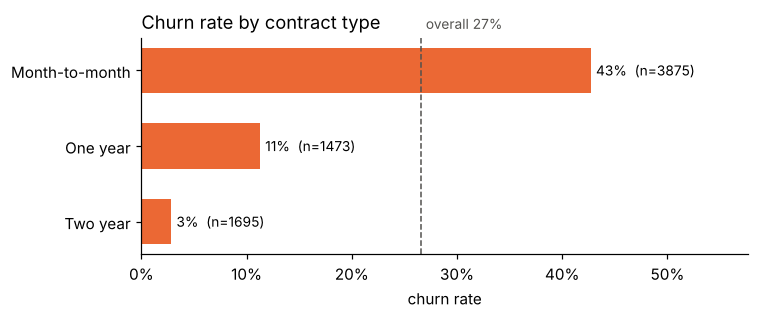

,churn_rate,customers
Contract,,
Month-to-month,0.427,3875
One year,0.113,1473
Two year,0.028,1695


In [7]:
def churn_rate_by(column):
    """Return churn rate and customer count for each value of a column, highest churn first."""
    table = df.groupby(column)["churn_flag"].agg(churn_rate="mean", customers="count")
    return table.sort_values("churn_rate", ascending=False)

def plot_churn_rate(table, title):
    """Horizontal bar chart of churn rate per group, with the overall rate as a reference line."""
    fig, ax = plt.subplots(figsize=(7, 0.6 * len(table) + 1.2))
    ax.barh(table.index.astype(str), table["churn_rate"], color=CHURN, height=0.6)
    ax.axvline(churn_rate, color="#52514e", linestyle="--", linewidth=1)
    ax.text(churn_rate + 0.005, -0.55, f"overall {churn_rate:.0%}", color="#52514e", fontsize=9)
    for i, (rate, n) in enumerate(zip(table["churn_rate"], table["customers"])):
        ax.text(rate + 0.005, i, f"{rate:.0%}  (n={n})", va="center", fontsize=9)
    ax.set_xlim(0, max(table["churn_rate"]) * 1.35)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("churn rate")
    ax.set_title(title, loc="left")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()

by_contract = churn_rate_by("Contract")
plot_churn_rate(by_contract, "Churn rate by contract type")
by_contract.round(3)

Month-to-month customers churn far more than customers on a one or two year contract.
This is the single strongest pattern in the data.

### 3.3 Churn rate by tenure (how long they have been a customer)

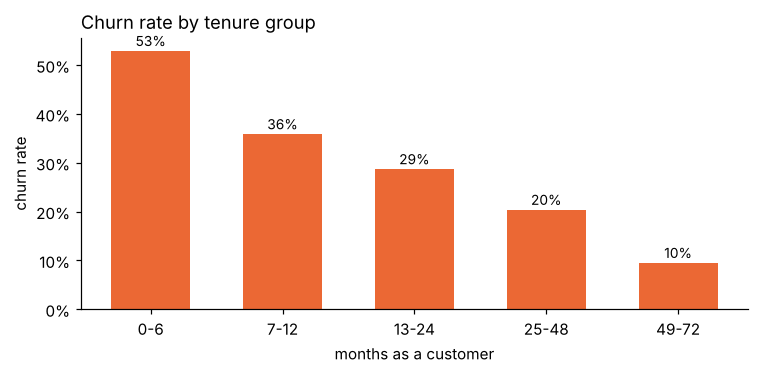

,churn_rate,customers
tenure_group,,
0-6,0.529,1481
7-12,0.359,705
13-24,0.287,1024
25-48,0.204,1594
49-72,0.095,2239


In [8]:
# Group tenure (months) into buckets so the pattern is easy to read
bins = [0, 6, 12, 24, 48, 72]
labels = ["0-6", "7-12", "13-24", "25-48", "49-72"]
df["tenure_group"] = pd.cut(df["tenure"], bins=bins, labels=labels, include_lowest=True)

by_tenure = df.groupby("tenure_group", observed=True)["churn_flag"].agg(churn_rate="mean", customers="count")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(by_tenure.index.astype(str), by_tenure["churn_rate"], color=CHURN, width=0.6)
for i, rate in enumerate(by_tenure["churn_rate"]):
    ax.text(i, rate + 0.01, f"{rate:.0%}", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("months as a customer")
ax.set_ylabel("churn rate")
ax.set_title("Churn rate by tenure group", loc="left")
plt.tight_layout()
plt.show()

by_tenure.round(3)

Churn is heavily front loaded: new customers are the ones at risk, and the rate drops steadily
the longer someone stays.

### 3.4 Monthly charges: do churners pay more?

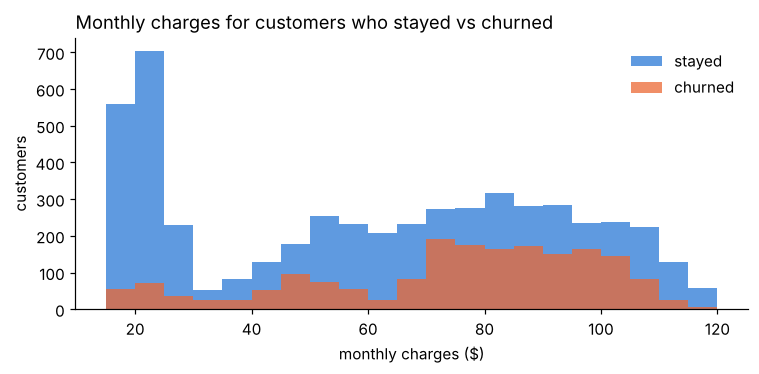

Churn
No     64.43
Yes    79.65
Name: median monthly charges, dtype: float64

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.arange(15, 125, 5)
ax.hist(df.loc[df["Churn"] == "No", "MonthlyCharges"], bins=bins, color=STAY, alpha=0.75, label="stayed")
ax.hist(df.loc[df["Churn"] == "Yes", "MonthlyCharges"], bins=bins, color=CHURN, alpha=0.75, label="churned")
ax.set_xlabel("monthly charges ($)")
ax.set_ylabel("customers")
ax.set_title("Monthly charges for customers who stayed vs churned", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

df.groupby("Churn")["MonthlyCharges"].median().round(2).rename("median monthly charges")

Customers who left were paying noticeably more per month. Cheap plans (under about $30, mostly phone only)
almost never churn.

### 3.5 Churn rate by payment method and internet service

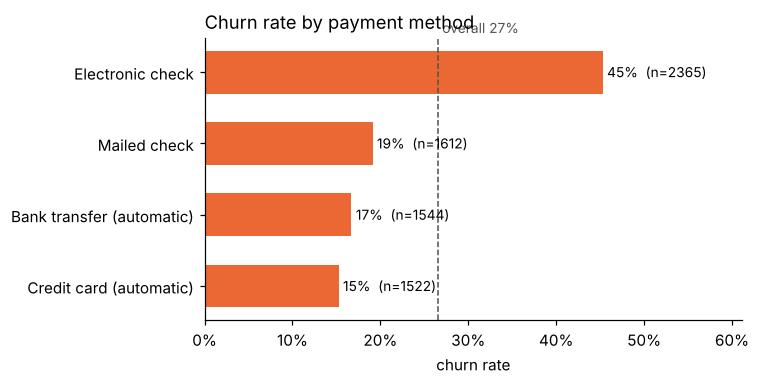

,churn_rate,customers
PaymentMethod,,
Electronic check,0.453,2365
Mailed check,0.191,1612
Bank transfer (automatic),0.167,1544
Credit card (automatic),0.152,1522


In [10]:
by_payment = churn_rate_by("PaymentMethod")
plot_churn_rate(by_payment, "Churn rate by payment method")
by_payment.round(3)

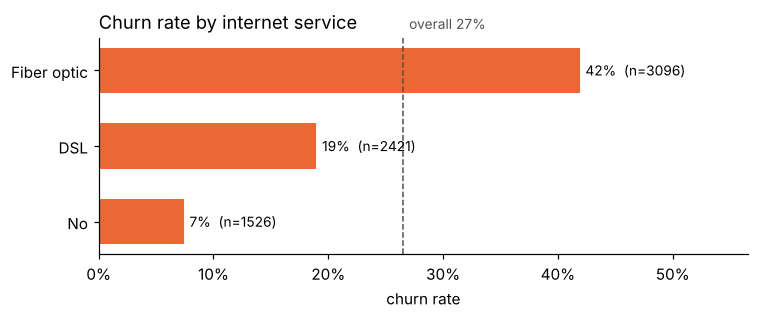

,churn_rate,customers
InternetService,,
Fiber optic,0.419,3096
DSL,0.190,2421
No,0.074,1526


In [11]:
by_internet = churn_rate_by("InternetService")
plot_churn_rate(by_internet, "Churn rate by internet service")
by_internet.round(3)

### 3.6 A quick scan of every yes/no feature

Instead of plotting each column, here is one table with the churn rate for every category of every
text column. This is a cheap way to spot which features matter before building a model.

In [12]:
# Every non numeric column except the target itself
category_columns = [c for c in df.select_dtypes(exclude="number").columns if c != "Churn"]

rows = []
for col in category_columns:
    for value, group in df.groupby(col):
        rows.append({"feature": col, "value": value, "churn_rate": group["churn_flag"].mean(), "customers": len(group)})

summary = pd.DataFrame(rows)
# Show the 12 groups with the highest churn rate (ignore tiny groups)
summary[summary["customers"] >= 200].sort_values("churn_rate", ascending=False).head(12).round(3)

,feature,value,churn_rate,customers
43,tenure_group,0-6,0.529,1481
41,PaymentMethod,Electronic check,0.453,2365
34,Contract,Month-to-month,0.427,3875
14,InternetService,Fiber optic,0.419,3096
16,OnlineSecurity,No,0.418,3498
3,SeniorCitizen,Yes,0.417,1142
25,TechSupport,No,0.416,3473
19,OnlineBackup,No,0.399,3088
22,DeviceProtection,No,0.391,3095
44,tenure_group,7-12,0.359,705


## 4. A simple churn model (logistic regression)

Goal: predict `Churn` from the customer's plan and billing details. I use logistic regression because
it is simple, fast, and the coefficients tell you *which* features push a customer toward churn.
That makes it easy to explain to a non technical stakeholder.

Steps:

1. Turn text columns into 0/1 dummy columns (one hot encoding).
2. Split into a training set (80%) and a test set (20%), keeping the churn ratio the same in both.
3. Scale the numeric columns so they are on a similar range to the 0/1 columns.
4. Fit the model and check it on the test set it has never seen.

In [13]:
features = df.drop(columns=["Churn", "churn_flag", "tenure_group"])
target = df["churn_flag"]

# One hot encode the text columns (drop_first avoids duplicate information)
X = pd.get_dummies(features, drop_first=True).astype(float)
print("number of model inputs:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(X, target, test_size=0.2, random_state=42, stratify=target)

# Scale the three numeric columns only; the dummy columns are already 0/1
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(f"accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"precision: {precision_score(y_test, y_pred):.3f}   (of the customers flagged as churn, how many really churned)")
print(f"recall   : {recall_score(y_test, y_pred):.3f}   (of the customers who really churned, how many we caught)")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob):.3f}   (0.5 = random guessing, 1.0 = perfect ranking)")

number of model inputs: 30
accuracy : 0.806
precision: 0.659   (of the customers flagged as churn, how many really churned)
recall   : 0.559   (of the customers who really churned, how many we caught)
ROC AUC  : 0.842   (0.5 = random guessing, 1.0 = perfect ranking)


In [14]:
# Confusion matrix: rows = actual, columns = predicted
cm = confusion_matrix(y_test, y_pred)
pd.DataFrame(cm, index=["actual: stayed", "actual: churned"], columns=["predicted: stayed", "predicted: churned"])

,predicted: stayed,predicted: churned
actual: stayed,927,108
actual: churned,165,209


A naive model that always says "stayed" would be right about 73% of the time, so accuracy alone is not
very informative here. Recall matters more for a retention team: it tells you what share of real churners
the model would put on their call list.

### Which features drive the prediction?

A positive coefficient means the feature pushes the prediction toward churn; a negative one pushes toward staying.

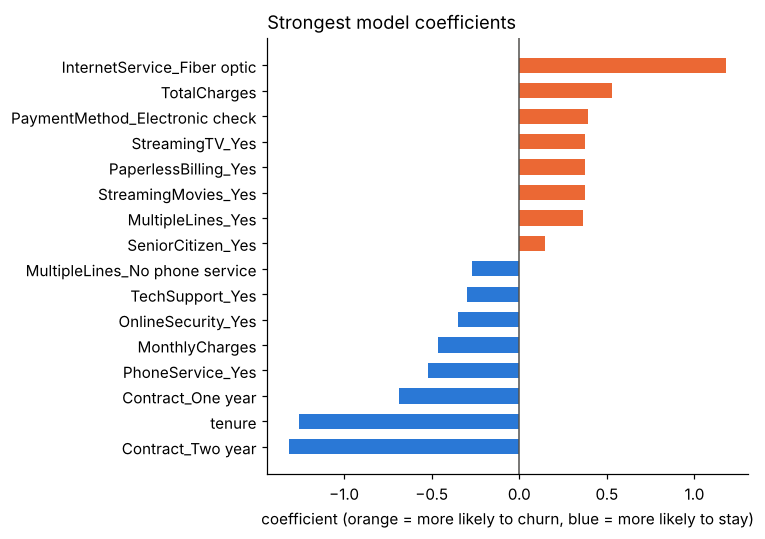

Contract_Two year                -1.314
tenure                           -1.257
Contract_One year                -0.684
PhoneService_Yes                 -0.521
MonthlyCharges                   -0.467
OnlineSecurity_Yes               -0.349
TechSupport_Yes                  -0.299
MultipleLines_No phone service   -0.269
SeniorCitizen_Yes                 0.148
MultipleLines_Yes                 0.362
StreamingMovies_Yes               0.373
PaperlessBilling_Yes              0.374
StreamingTV_Yes                   0.375
PaymentMethod_Electronic check    0.393
TotalCharges                      0.528
InternetService_Fiber optic       1.181
dtype: float64

In [15]:
coefficients = pd.Series(model.coef_[0], index=X.columns).sort_values()
top = pd.concat([coefficients.head(8), coefficients.tail(8)])

fig, ax = plt.subplots(figsize=(7, 5))
colors = [CHURN if v > 0 else STAY for v in top]
ax.barh(top.index, top.values, color=colors, height=0.6)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_xlabel("coefficient (orange = more likely to churn, blue = more likely to stay)")
ax.set_title("Strongest model coefficients", loc="left")
plt.tight_layout()
plt.show()

top.round(3)

## 5. What this means

**Key findings (numbers come from the cells above):**

- 26.5% of the 7,043 customers churned.
- Contract type is the biggest single factor: 43% of month-to-month customers left, versus 11% on one year and 3% on two year contracts.
- Churn is front loaded. 53% of customers in their first 6 months left, compared with under 10% of customers past 4 years.
- Customers who churned paid more per month (median $79.65 vs $64.43). Fiber optic internet customers churn at 42%, DSL at 19%.
- Paying by electronic check goes with a 45% churn rate; automatic bank transfer or credit card sit around 15 to 17%.
- Customers without add-ons like online security or tech support churn at about 42%.
- The logistic regression gets accuracy 0.81, ROC AUC 0.84, precision 0.66 and recall 0.56 on the held out test set. It catches a bit over half of real churners while being wrong about one in three of the customers it flags.

**What a business could do with this:**

- Target retention offers (discount for switching to an annual contract) at month-to-month customers in their first year, especially fiber customers paying by electronic check.
- Nudge customers toward automatic payment methods. Whether electronic check *causes* churn or just goes with it is unclear, but it is a cheap, low risk change to test.
- Bundle security and tech support into fiber plans, since customers with those add-ons leave less often.
- Use the model's churn probability to rank customers for outreach rather than treating its yes/no answer as final. Lowering the decision threshold would catch more churners at the cost of more false alarms.

**Limitations:**

- One snapshot in time, no dates, so I can't look at trends or how churn evolves after a price change.
- The model only finds patterns, not causes. A high monthly charge may just be a proxy for fiber plans with many add-ons.
- `tenure`, `MonthlyCharges` and `TotalCharges` are closely related (total is roughly tenure times monthly), which makes their individual coefficients hard to interpret on their own.
- No tuning was done. A tuned threshold, class weights or a tree based model would likely improve recall.